# TVL daily event study

Appendix Table 5.5.

In [1]:
from pathlib import Path
import os

# Locate the bundle from either its root or the notebooks directory.
_here = Path.cwd().resolve()
_ROOT = next((p for p in [_here, *_here.parents]
              if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if _ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Tesi_codice_consegna folder.")
_DATA_DIR = _ROOT / "data"
_OUTPUT_DIR = _ROOT / "results" / "rerun" / "07_tvl_event_study"
_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(_OUTPUT_DIR)
print("Data:", _DATA_DIR)
print("New outputs:", _OUTPUT_DIR)


Data: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/data
New outputs: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/results/rerun/07_tvl_event_study


## Daily sensitivity to the Fed funds series

Original source retained. It estimates days -10 to +20; Appendix Table 5.5 displays the -2 to +20 subset. The archived numeric outputs reproduce that subset.

Source: `AAVE v2/TVL DELLA TESI CON SENSITIVITA.ipynb`, original cell 4 (zero-based).

07_tvl_event_study.ipynb:cell3:125: SyntaxWarning: invalid escape sequence '\g'
07_tvl_event_study.ipynb:cell3:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
07_tvl_event_study.ipynb:cell3:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
Dati caricati e preparati con successo.

==================== INIZIO ANALISI SU: tvl% ====================
Analisi su 24 eventi FOMC (escluse le crisi).
Esecuzione regressioni giorno per giorno...

--- Risultati per tvl% ---
+-------------+---------------+---------------+----------------+
|   Event Day |   coef_target |   pval_target |   rsquared_adj |
+=============+===============+===============+================+
|         -10 |       -0.0000 |        0.3588 |        -0.0777

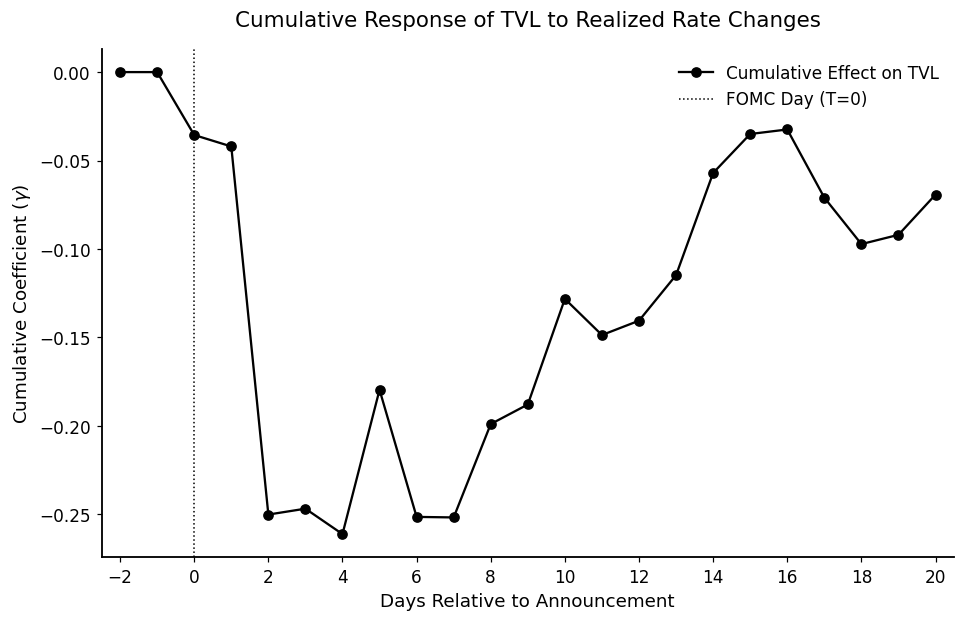

In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from tabulate import tabulate
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# =============================================================================
# --- 1. CONFIGURAZIONE E CARICAMENTO ---
# =============================================================================
try:
    # Carica il tuo CSV principale che contiene GIÀ 'tvl%'
    df_analysis = pd.read_csv(str(_DATA_DIR / 'aavetvl.csv'), parse_dates=['date'], dayfirst=True).set_index('date')
    
    # Carica le date FOMC
    df_surprises = pd.read_csv(str(_DATA_DIR / 'ABJ-2024.csv'), parse_dates=['date'], dayfirst=True).set_index('date')
    
    # Definisci le colonne
    DEPENDENT_VAR = 'tvl%'
    CONTROLS = ['ethperpetual', 'gas%', 'S&P 500', 'VIX']
    RISK_FREE_COL = 'FEDFUNDS'
    
    # Pulisci i dati
    df_analysis.dropna(subset=[DEPENDENT_VAR] + CONTROLS + [RISK_FREE_COL], inplace=True)
    print("Dati caricati e preparati con successo.")

except Exception as e:
    print(f"ERRORE durante la preparazione dei dati: {e}")
    exit()

# =============================================================================
# --- 2. EVENT STUDY SUL TVL (VARIAZIONE TOTALE) ---
# =============================================================================
print(f"\n{'='*20} INIZIO ANALISI SU: {DEPENDENT_VAR} {'='*20}")

# --- Setup ---
EVENT_WINDOW_START = -10
EVENT_WINDOW_END = 20
event_window_days = np.arange(EVENT_WINDOW_START, EVENT_WINDOW_END + 1)
fomc_dates = df_surprises.index[df_surprises.index.isin(df_analysis.index)]

# Escludi le date di crisi
crisis_fomc_dates = pd.to_datetime(['2022-06-15', '2022-11-02', '2023-03-22'])
fomc_dates = fomc_dates[~fomc_dates.isin(crisis_fomc_dates)]
print(f"Analisi su {len(fomc_dates)} eventi FOMC (escluse le crisi).")

# --- Calcolo della variazione del tasso risk-free ---
df_analysis['rf_diff'] = df_analysis[RISK_FREE_COL].diff()

# --- Esecuzione Regressioni ---
results_list = []
print("Esecuzione regressioni giorno per giorno...")
for d in event_window_days:
    target_dates = fomc_dates + pd.DateOffset(days=d)
    day_df = df_analysis.loc[target_dates[target_dates.isin(df_analysis.index)]].copy()
    
    if len(day_df) < 20: continue

    # Variabile dipendente (Y) è già pronta: 'tvl%'
    y = day_df[DEPENDENT_VAR]

    # Variabile indipendente principale: Variazione Cumulata
    cum_changes = []
    for idx in day_df.index:
        event_date = idx - pd.DateOffset(days=d)
        cum_change = 0.0
        if d >= 0:
            cum_change = df_analysis.loc[event_date:idx, 'rf_diff'].sum()
        cum_changes.append(cum_change)
    day_df['cumulative_rf_change'] = cum_changes

    # Matrice X finale
    X = day_df[['cumulative_rf_change'] + CONTROLS]
    X = sm.add_constant(X)
    
    # Stima del modello (NON usiamo AR, ma la variabile diretta)
    model = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
    
    results_list.append({
        'Event Day': d,
        'coef_target': model.params['cumulative_rf_change'],
        'pval_target': model.pvalues['cumulative_rf_change'],
        'rsquared_adj': model.rsquared_adj,
        'ci_lower': model.conf_int().loc['cumulative_rf_change'][0],
        'ci_upper': model.conf_int().loc['cumulative_rf_change'][1],
    })
    
df_results = pd.DataFrame(results_list).set_index('Event Day')

# --- 3. Stampa e Visualizzazione ---
print(f"\n--- Risultati per {DEPENDENT_VAR} ---")
print(tabulate(df_results[['coef_target', 'pval_target', 'rsquared_adj']], headers='keys', tablefmt='grid', floatfmt=".4f"))

if not df_results.empty:
    df_results['cumulative_coef'] = df_results['coef_target'].cumsum()

    # --- SETUP DEL GRAFICO "STILE PAPER" ---
    # Iniziamo con uno stile di base pulito, poi lo personalizziamo
    plt.style.use('default') # Resetta a uno stile base
    fig, ax = plt.subplots(figsize=(10, 6)) # Formato più orizzontale

    # --- FILTRA I DATI PER LA FINESTRA RISTRETTA ---
    start_day = -2
    plot_data = df_results.loc[start_day:]

    # --- PLOT PRINCIPALE ---
    ax.plot(
        plot_data.index, 
        plot_data['cumulative_coef'], 
        marker='o',          # Marcatori circolari
        linestyle='-',       # Linea solida
        color='black',       # Colore nero per uno stile sobrio
        label='Cumulative Effect on TVL',
        linewidth=1.5,
        markersize=6
    )

    # --- LINEE DI RIFERIMENTO ---
    # ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='black', linestyle=':', linewidth=1, label='FOMC Day (T=0)')

    # --- TITOLI ED ETICHETTE (più compatti) ---
    ax.set_title('Cumulative Response of TVL to Realized Rate Changes', fontsize=14, pad=15)
    ax.set_xlabel('Days Relative to Announcement', fontsize=12)
    ax.set_ylabel('Cumulative Coefficient ($\gamma$)', fontsize=12)

    # --- FORMATTAZIONE DEGLI ASSI ---
    # Imposta i limiti e i tick dell'asse X
    ax.set_xlim(start_day - 0.5, plot_data.index.max() + 0.5)
    ax.set_xticks(np.arange(start_day, plot_data.index.max() + 1, 2))
    
    # Rimuovi la griglia o rendila molto leggera
    ax.grid(False) # Niente griglia per un look più pulito
    # In alternativa, per una griglia leggera:
    # ax.grid(True, which='major', axis='y', linestyle=':', linewidth='0.5', color='lightgray')

    # Aumenta la dimensione dei tick
    ax.tick_params(axis='both', which='major', labelsize=11)

    # --- LEGENDA E BORDI ---
    ax.legend(fontsize=11, loc='upper right', frameon=False) # 'frameon=False' toglie il riquadro

    # Mantieni solo gli assi inferiore e sinistro per un look da "grafico scientifico"
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)

    # --- SALVATAGGIO ---
    output_filename_tvl = "event_study_tvl_academic.pdf"
    plt.savefig(output_filename_tvl, format='pdf', dpi=300, bbox_inches='tight')

    plt.show()
    
    print(f"\nGrafico 'stile paper' salvato come: {output_filename_tvl}")